# Hard Hat Detection – Computer Vision Project
### YOLOv8 Object Detection


## 1. Install and import libraries



In [1]:
!pip -q install ultralytics

In [2]:
import os
import glob
import random
import shutil
import zipfile
from pathlib import Path
from collections import Counter

import cv2
import yaml
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from ultralytics import YOLO
from IPython.display import display, Image as IPyImage, Video

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU. Training will be much slower.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [3]:
import os
import zipfile
import shutil
from pathlib import Path

ZIP_PATH = "/content/Hard Hat Workers.v1-resize-416x416-reflect.yolov5pytorch.zip"

DATASET_DIR = Path("/content/hardhat_dataset")

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError("Dataset ZIP file not found!")

if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)

DATASET_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATASET_DIR)

print("Dataset extracted successfully!")
print("Files:", list(DATASET_DIR.iterdir())[:10])

Dataset extracted successfully!
Files: [PosixPath('/content/hardhat_dataset/data.yaml'), PosixPath('/content/hardhat_dataset/test'), PosixPath('/content/hardhat_dataset/README.roboflow.txt'), PosixPath('/content/hardhat_dataset/README.dataset.txt'), PosixPath('/content/hardhat_dataset/train')]


In [4]:
for path in sorted(DATASET_DIR.iterdir()):
    print(path.name, "directory" if path.is_dir() else "file")

for split in ["train", "test"]:
    for sub in ["images", "labels"]:
        folder = DATASET_DIR / split / sub
        print(f"{split}/{sub} exists:", folder.exists(),
              "| files:", len(list(folder.glob("*"))) if folder.exists() else 0)

README.dataset.txt file
README.roboflow.txt file
data.yaml file
test directory
train directory
train/images exists: True | files: 5269
train/labels exists: True | files: 5269
test/images exists: True | files: 1766
test/labels exists: True | files: 1766


## 4. Define class names and check image-label pairs

`  

In [5]:
CLASS_NAMES = ["head", "helmet", "person"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def get_images(folder):
    return sorted([p for p in Path(folder).iterdir()
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS])

def check_split(split):
    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"
    images = get_images(image_dir)
    missing_labels = []
    invalid_lines = []
    class_counts = Counter()
    empty_labels = 0

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.exists():
            missing_labels.append(image_path.name)
            continue

        lines = label_path.read_text().strip().splitlines()
        if not lines:
            empty_labels += 1

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()
            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")
                class_id = int(float(parts[0]))
                coords = [float(v) for v in parts[1:]]
                if class_id < 0 or class_id >= len(CLASS_NAMES):
                    raise ValueError("Class ID out of range")
                if not all(0 <= v <= 1 for v in coords):
                    raise ValueError("Coordinates must be between 0 and 1")
                class_counts[class_id] += 1
            except Exception as exc:
                invalid_lines.append((label_path.name, line_number, str(exc)))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Missing label files:", len(missing_labels))
    print("Empty label files:", empty_labels)
    print("Invalid annotation lines:", len(invalid_lines))
    print("Annotations per class:")
    for class_id, name in enumerate(CLASS_NAMES):
        print(f"  {name}: {class_counts[class_id]}")

    return images, class_counts, missing_labels, invalid_lines

train_images, train_counts, train_missing, train_invalid = check_split("train")
test_images, test_counts, test_missing, test_invalid = check_split("test")


TRAIN
Images: 5269
Missing label files: 0
Empty label files: 0
Invalid annotation lines: 0
Annotations per class:
  head: 6055
  helmet: 20024
  person: 773

TEST
Images: 1766
Missing label files: 0
Empty label files: 0
Invalid annotation lines: 0
Annotations per class:
  head: 2208
  helmet: 6482
  person: 225


## 5. Create a validation split from training

In [6]:
train_img_dir = DATASET_DIR / "train" / "images"
train_lbl_dir = DATASET_DIR / "train" / "labels"
valid_img_dir = DATASET_DIR / "valid" / "images"
valid_lbl_dir = DATASET_DIR / "valid" / "labels"

valid_img_dir.mkdir(parents=True, exist_ok=True)
valid_lbl_dir.mkdir(parents=True, exist_ok=True)

all_train_images = get_images(train_img_dir)
random.Random(SEED).shuffle(all_train_images)

validation_count = int(0.20 * len(all_train_images))
validation_images = all_train_images[:validation_count]

for image_path in validation_images:
    label_path = train_lbl_dir / f"{image_path.stem}.txt"
    if not label_path.exists():
        raise FileNotFoundError(f"Missing label for {image_path.name}")

    shutil.move(str(image_path), str(valid_img_dir / image_path.name))
    shutil.move(str(label_path), str(valid_lbl_dir / label_path.name))

print("Training images:", len(get_images(train_img_dir)))
print("Validation images:", len(get_images(valid_img_dir)))
print("Test images:", len(get_images(DATASET_DIR / "test" / "images")))

Training images: 4216
Validation images: 1053
Test images: 1766


## 6. Create the YOLO data configuration

We write a new `data.yaml` using absolute paths. The three class IDs are:

- `0`: head
- `1`: helmet
- `2`: person

In [7]:
DATA_YAML = DATASET_DIR / "data.yaml"

data_config = {
    "path": str(DATASET_DIR),
    "train": str(DATASET_DIR / "train" / "images"),
    "val": str(DATASET_DIR / "valid" / "images"),
    "test": str(DATASET_DIR / "test" / "images"),
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print(DATA_YAML.read_text())

path: /content/hardhat_dataset
train: /content/hardhat_dataset/train/images
val: /content/hardhat_dataset/valid/images
test: /content/hardhat_dataset/test/images
nc: 3
names:
- head
- helmet
- person



## 7. Visualize images and bounding boxes


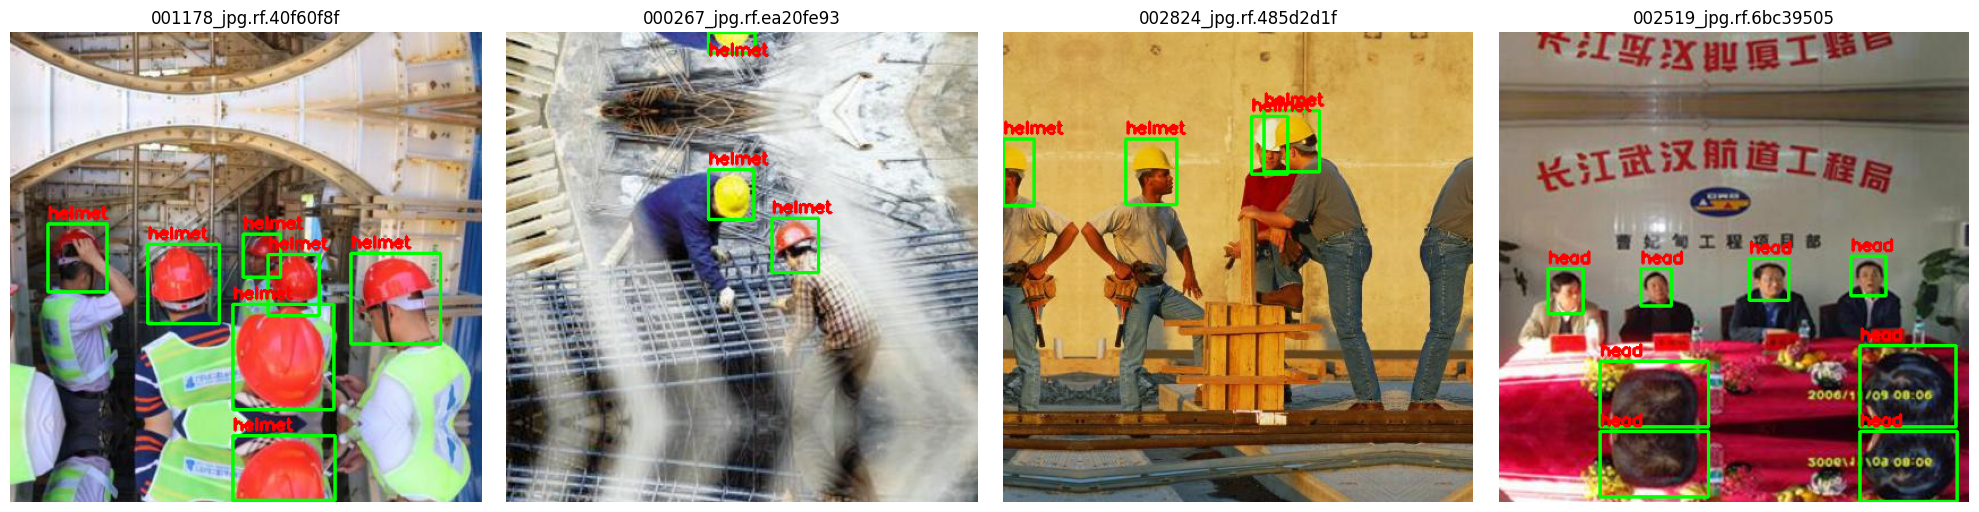

In [8]:
def show_yolo_samples(split="train", number=4):
    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"
    samples = get_images(image_dir)
    samples = random.sample(samples, min(number, len(samples)))

    fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 5))
    if len(samples) == 1:
        axes = [axes]

    for ax, image_path in zip(axes, samples):
        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]
        label_path = label_dir / f"{image_path.stem}.txt"

        if label_path.exists():
            for line in label_path.read_text().strip().splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue
                cls_id = int(float(parts[0]))
                x, y, bw, bh = map(float, parts[1:])
                x1 = int((x - bw / 2) * w)
                y1 = int((y - bh / 2) * h)
                x2 = int((x + bw / 2) * w)
                y2 = int((y + bh / 2) * h)
                cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(image, CLASS_NAMES[cls_id], (x1, max(20, y1 - 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

        ax.imshow(image)
        ax.axis("off")
        ax.set_title(image_path.name[:22])

    plt.tight_layout()
    plt.show()

show_yolo_samples("train", 4)

## 8. Plot class distribution



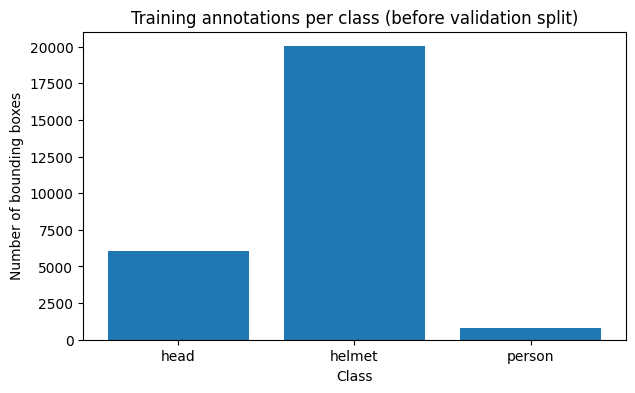

{'head': 6055, 'helmet': 20024, 'person': 773}


In [10]:
class_counts = {
    CLASS_NAMES[i]: train_counts[i] for i in range(len(CLASS_NAMES))
}
plt.figure(figsize=(7, 4))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Training annotations per class (before validation split)")
plt.xlabel("Class")
plt.ylabel("Number of bounding boxes")
plt.show()

print(class_counts)

## 9. Load a pretrained YOLOv8 model



In [11]:
model = YOLO("yolov8n.pt")
print("Model loaded.")
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Model loaded.
Device: GPU


## 10. Train the model



In [12]:
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
DEVICE = 0 if torch.cuda.is_available() else "cpu"

train_results = model.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=416,
    batch=BATCH_SIZE,
    device=DEVICE,
    patience=20,
    workers=2,
    pretrained=True,
    seed=SEED,
    project="/content/runs/hardhat",
    name="yolov8n_hardhat",
    exist_ok=True,
    plots=True,
    save=True,
    verbose=True
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hardhat_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_hardhat, nbs=64, nms=None, opset=None, optimize

## 11. Load the best trained weights



In [13]:
BEST_MODEL_PATH = "/content/runs/hardhat/yolov8n_hardhat/weights/best.pt"
if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError("best.pt was not created. Check the training output.")

best_model = YOLO(BEST_MODEL_PATH)
print("Loaded:", BEST_MODEL_PATH)
print("Class names:", best_model.names)

Loaded: /content/runs/hardhat/yolov8n_hardhat/weights/best.pt
Class names: {0: 'head', 1: 'helmet', 2: 'person'}


## 12. Review training curves

The plots help us check whether training and validation losses are improving and whether metrics are stable.

results.png


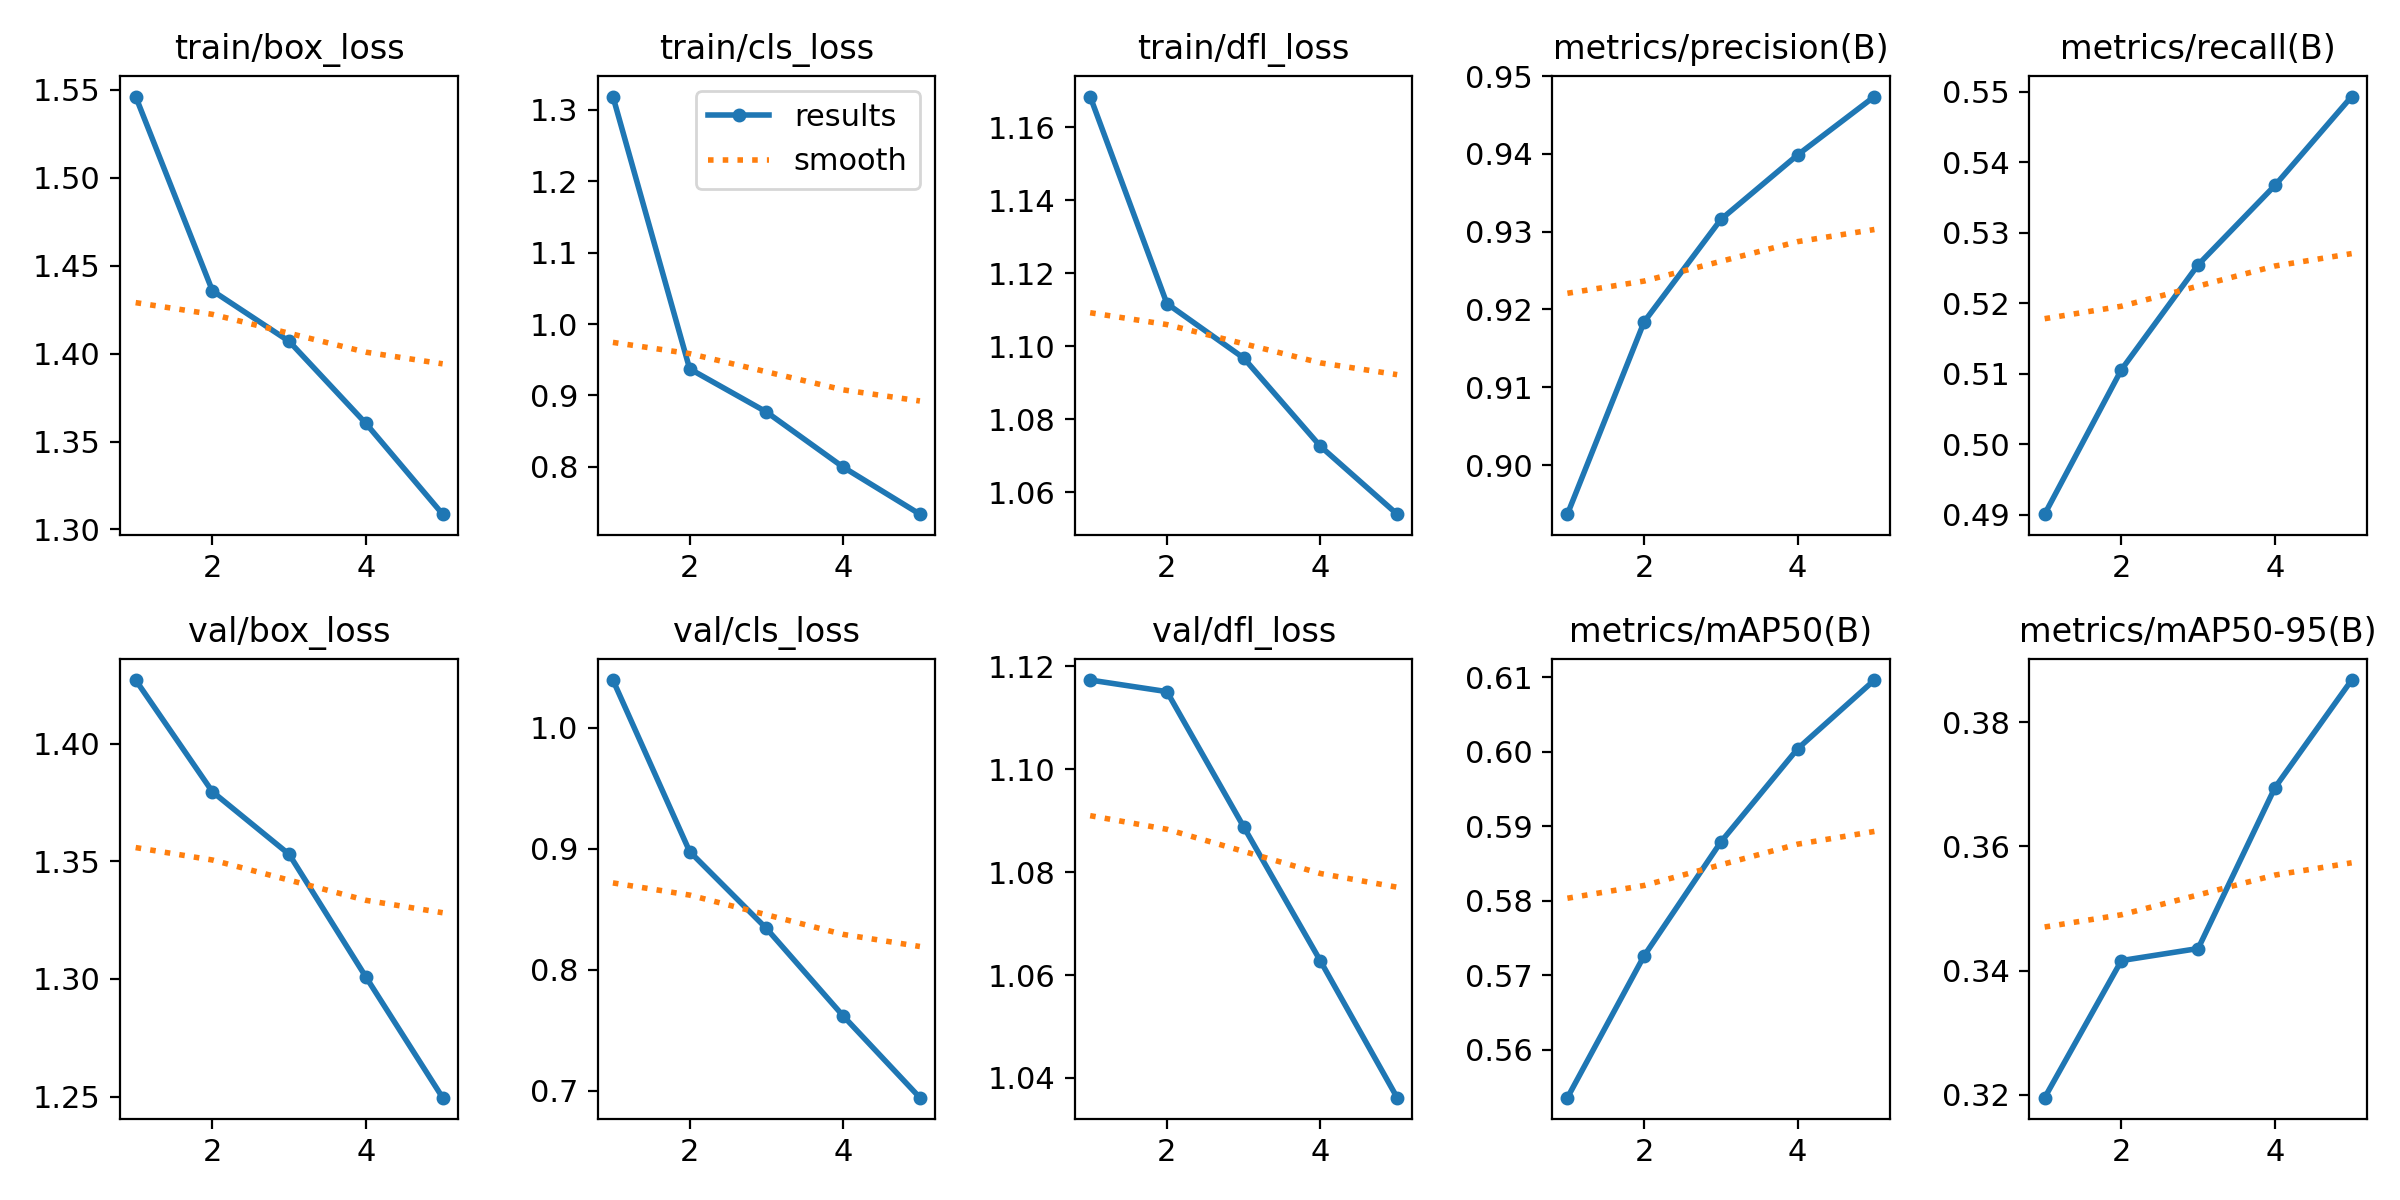

confusion_matrix.png


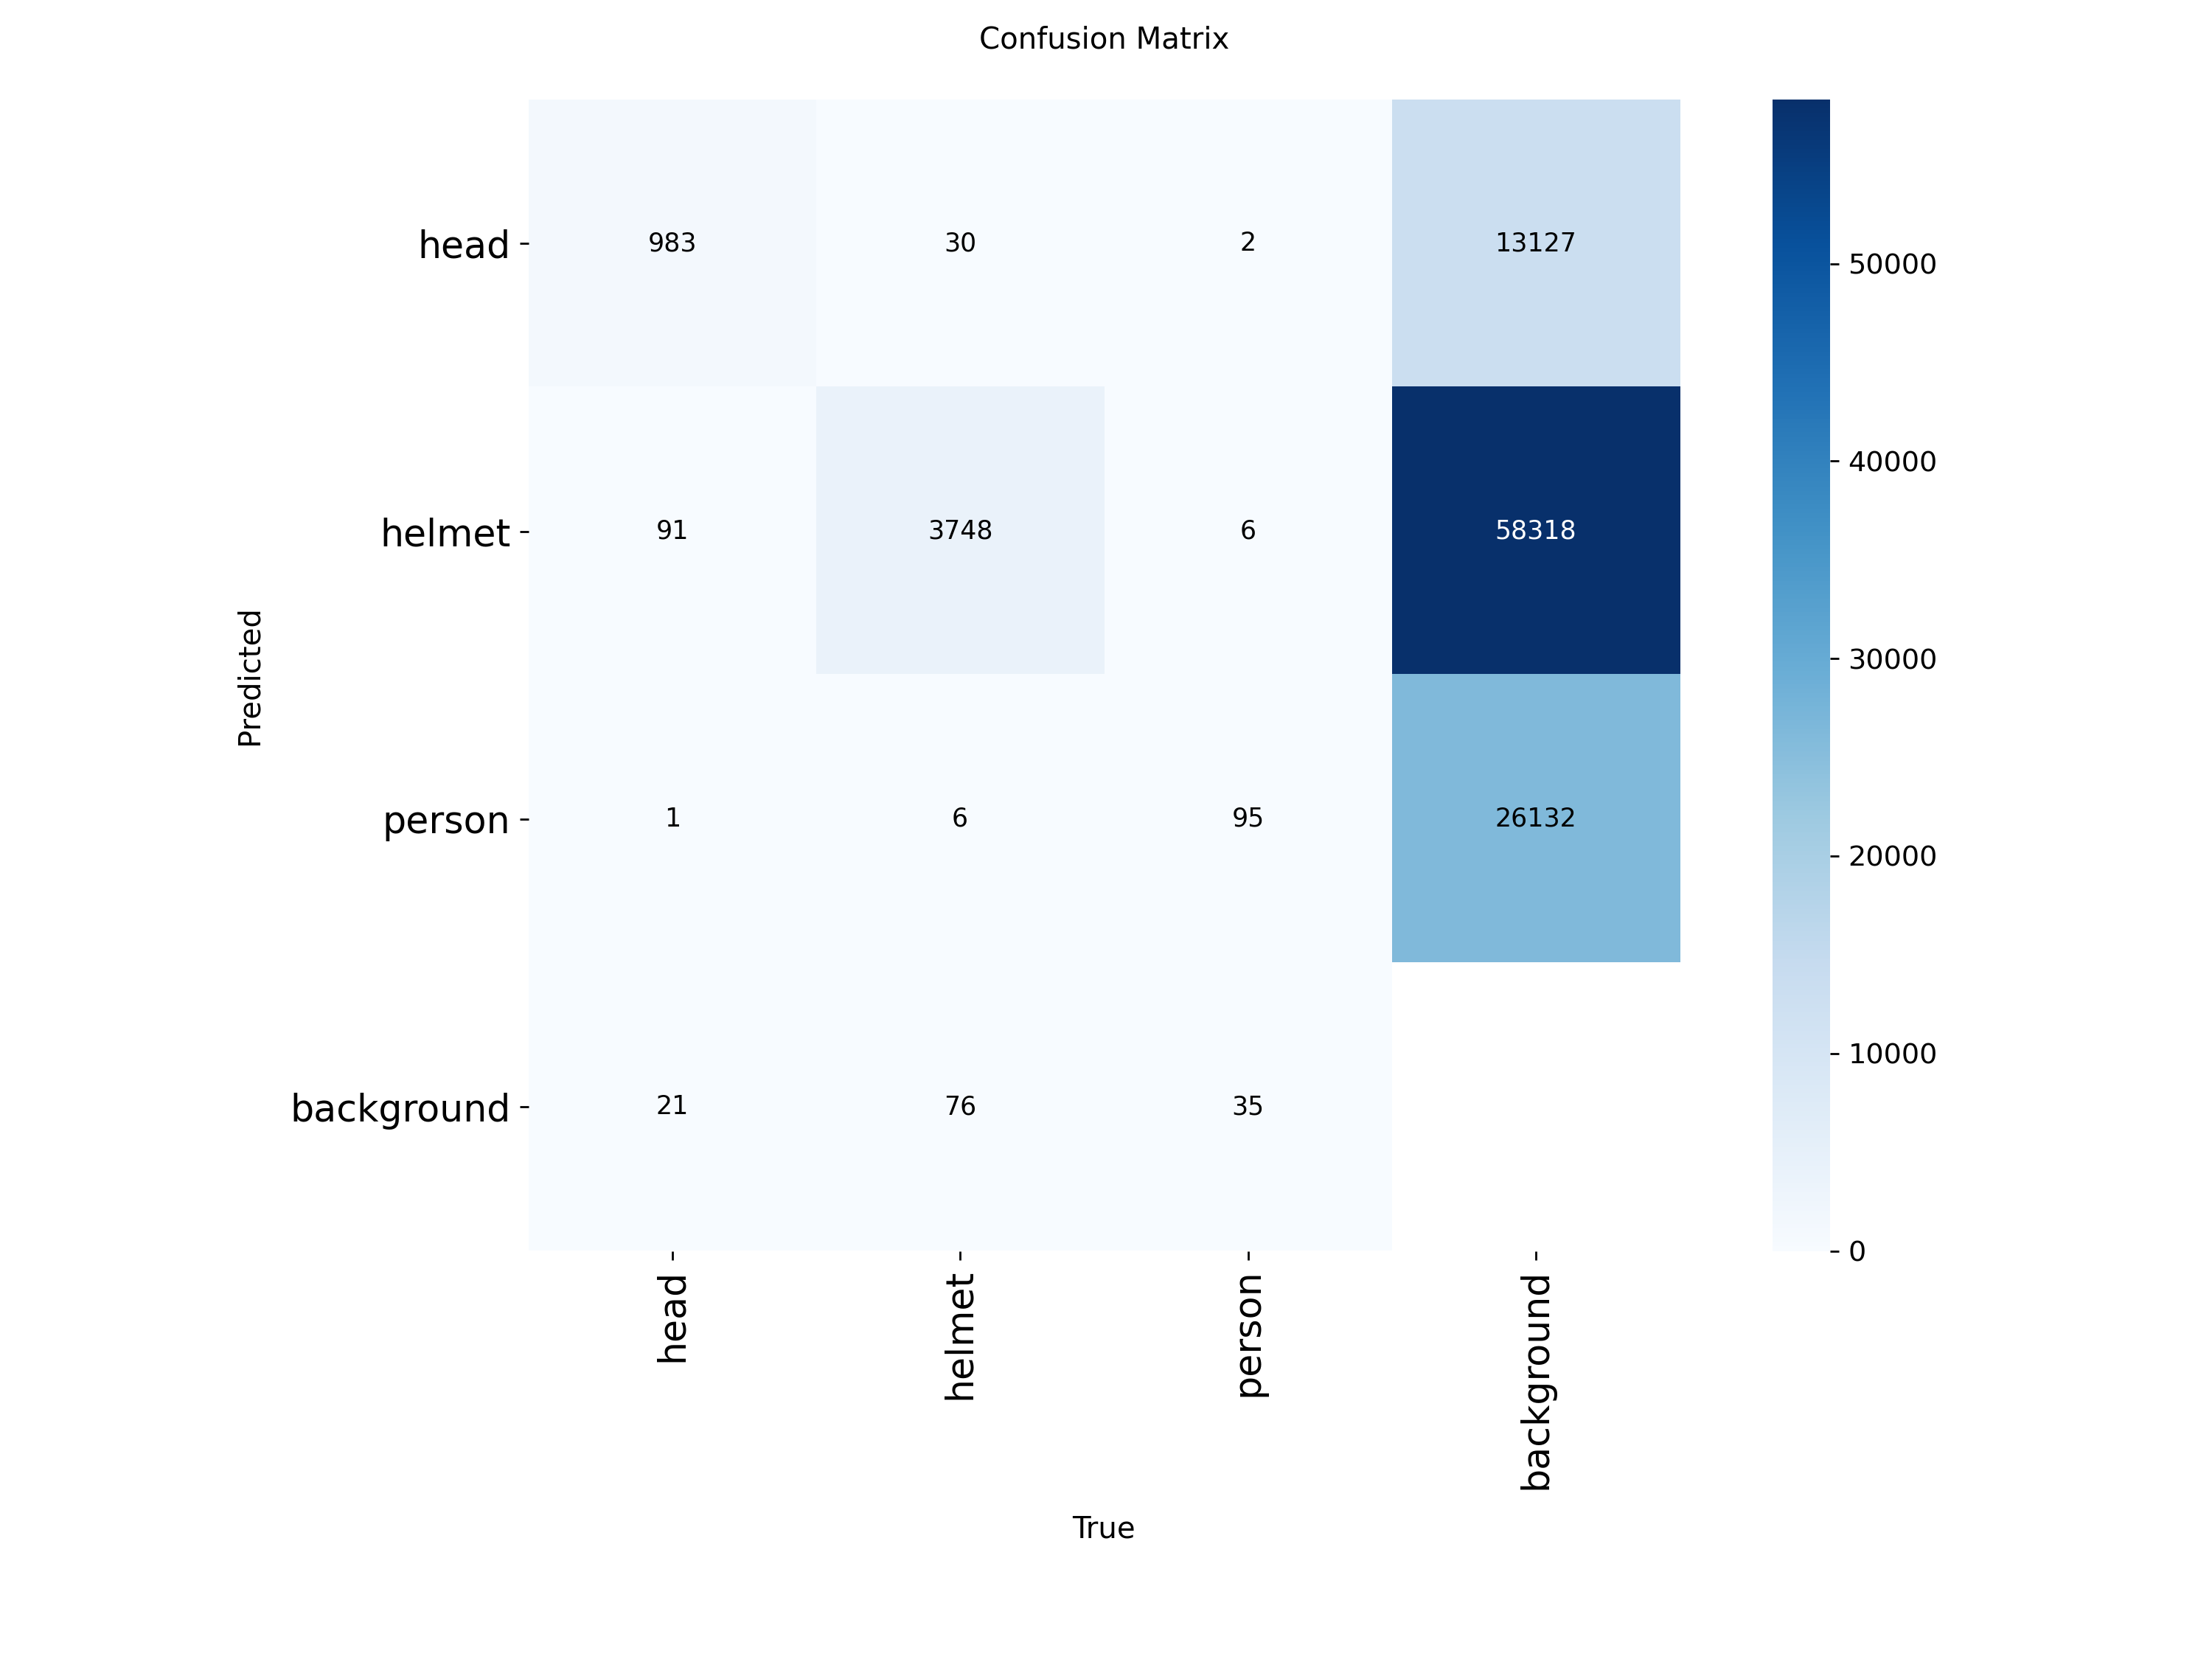

BoxPR_curve.png


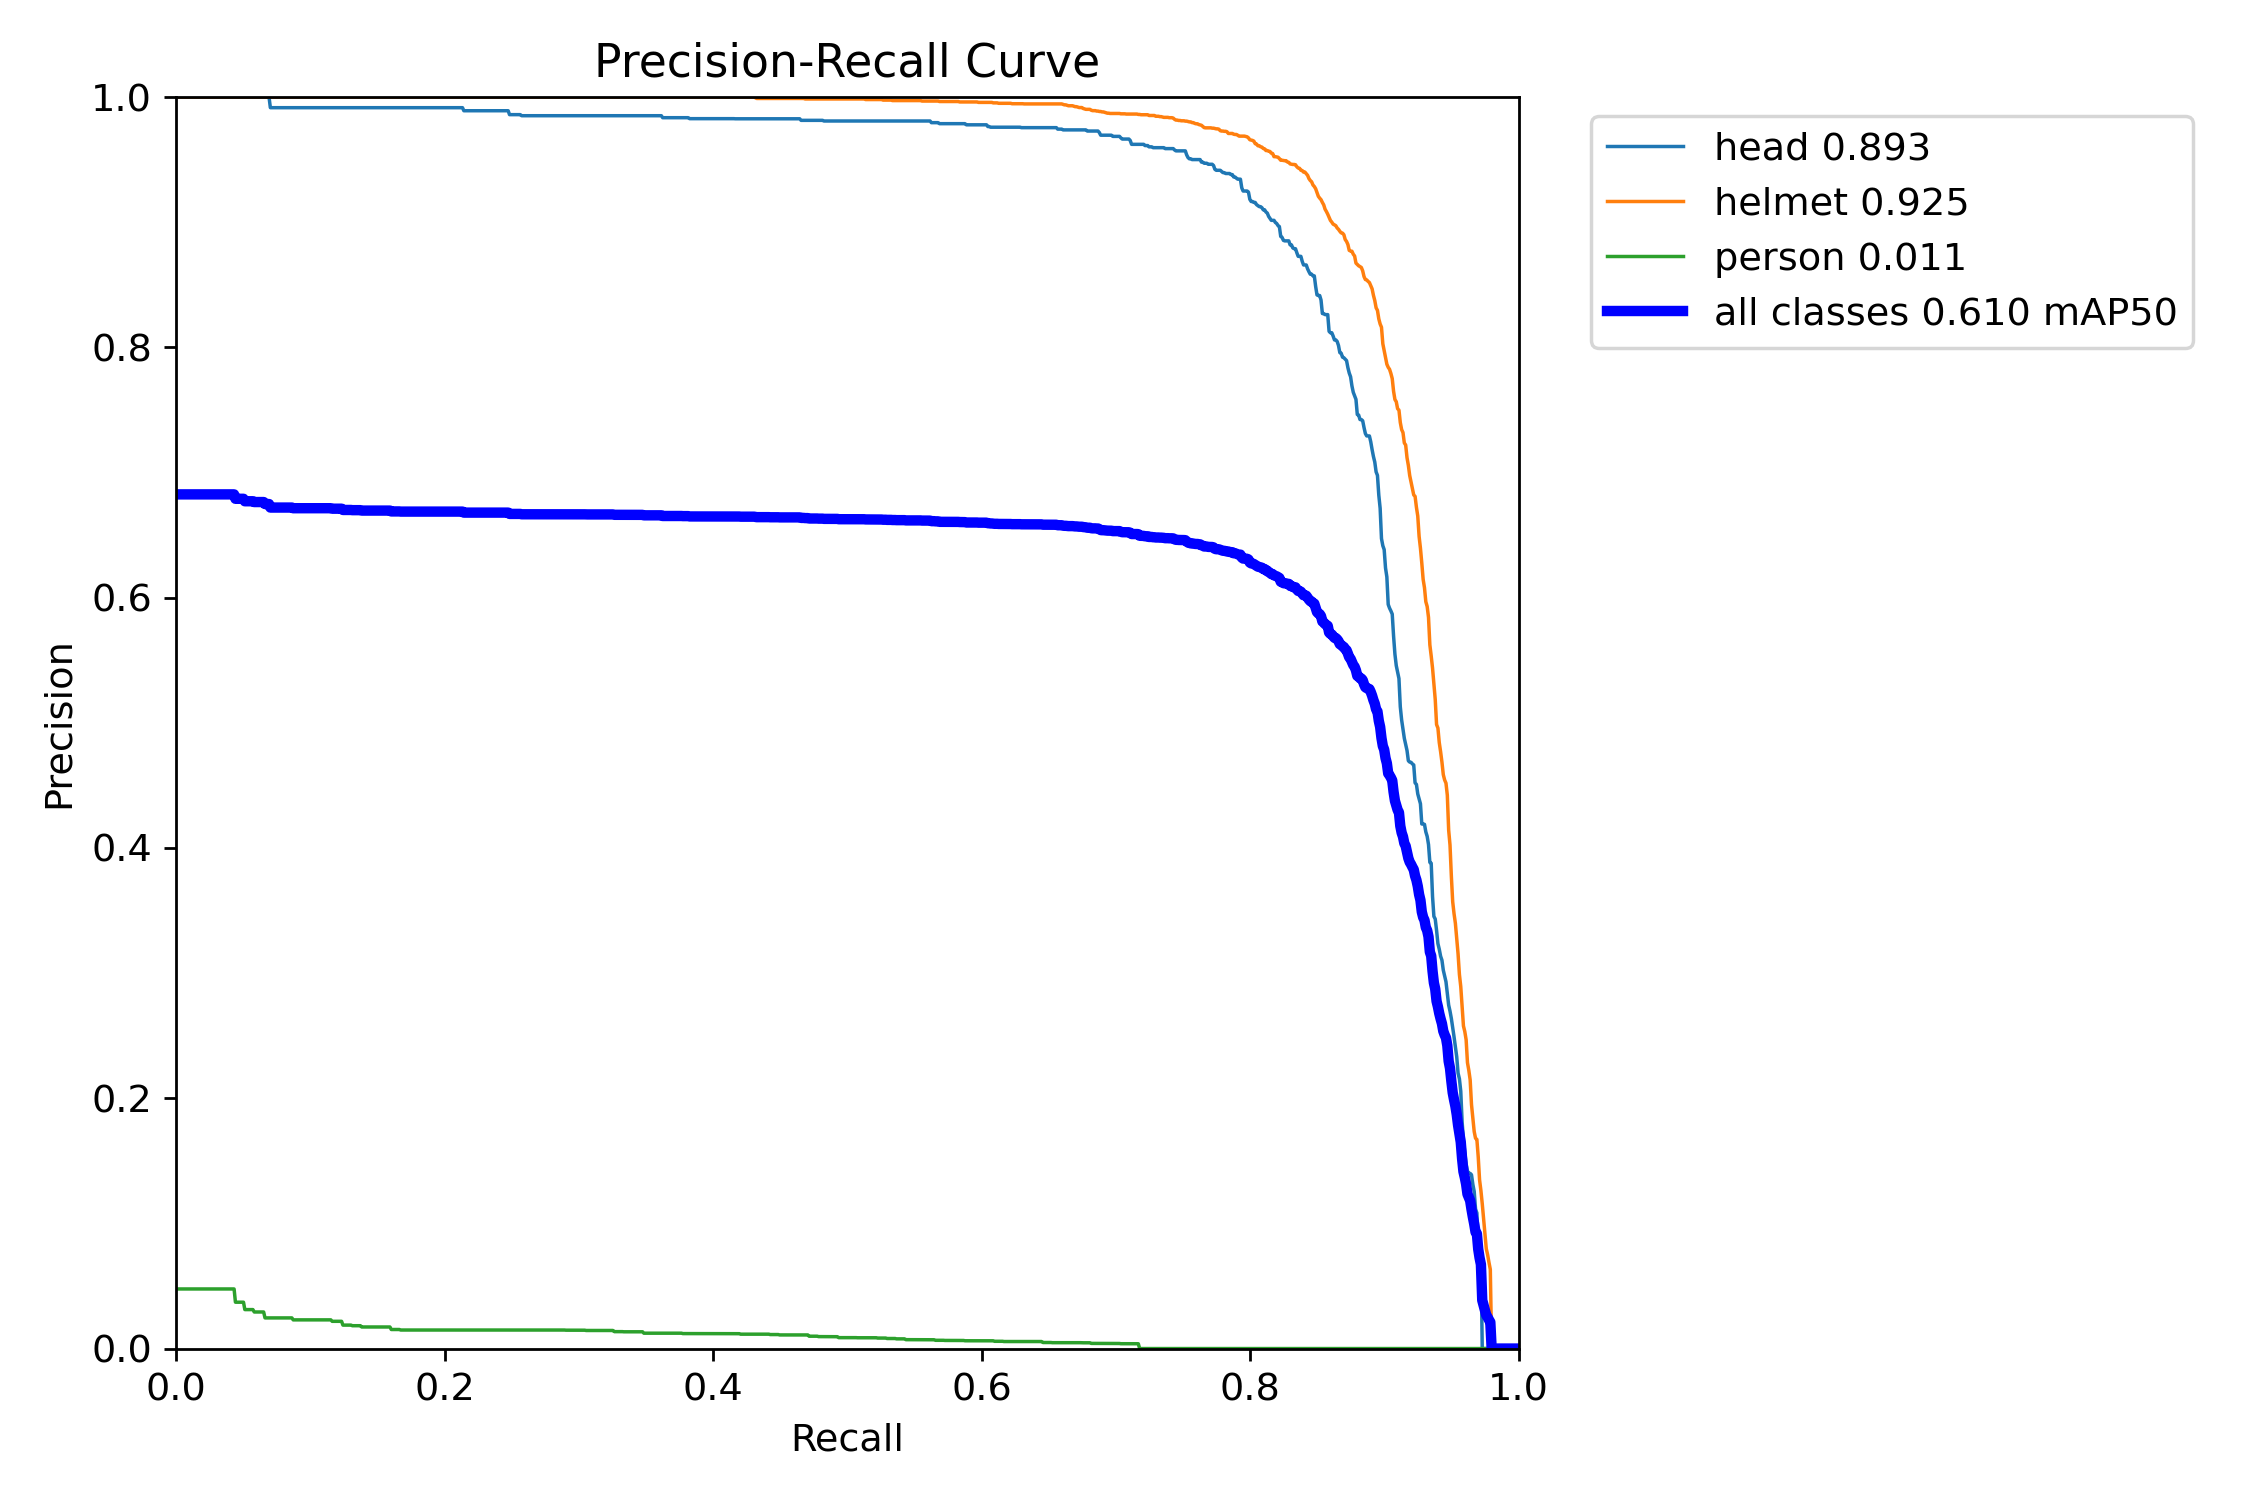

BoxF1_curve.png


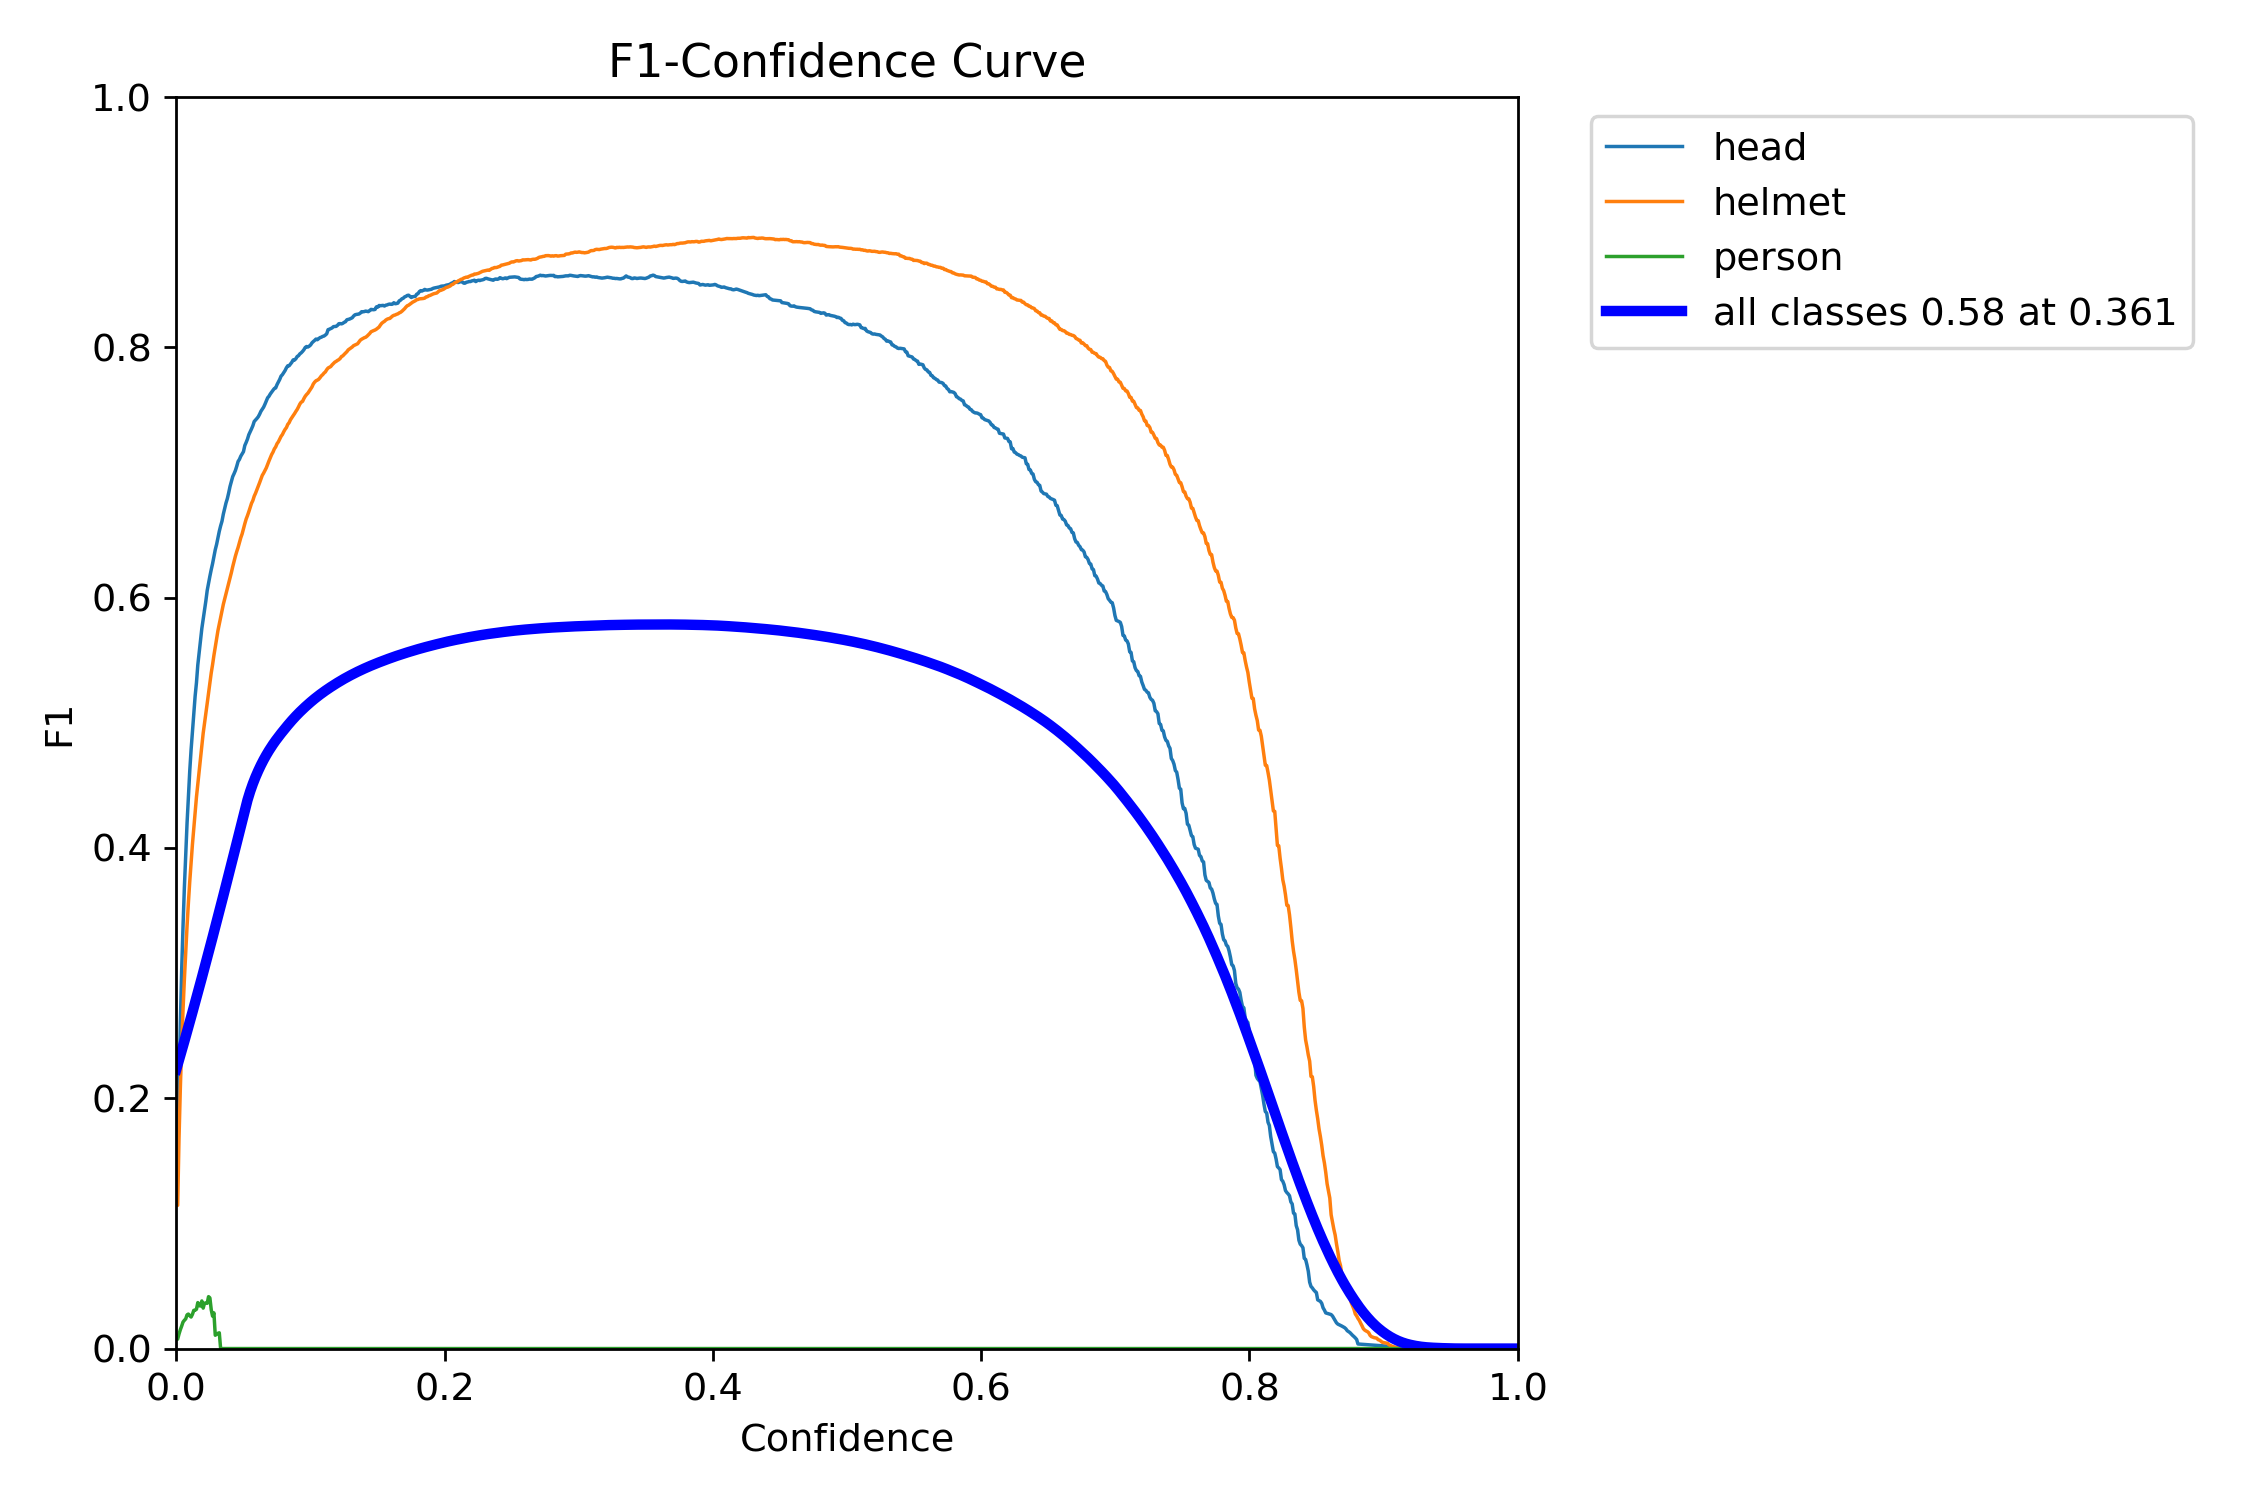

BoxP_curve.png


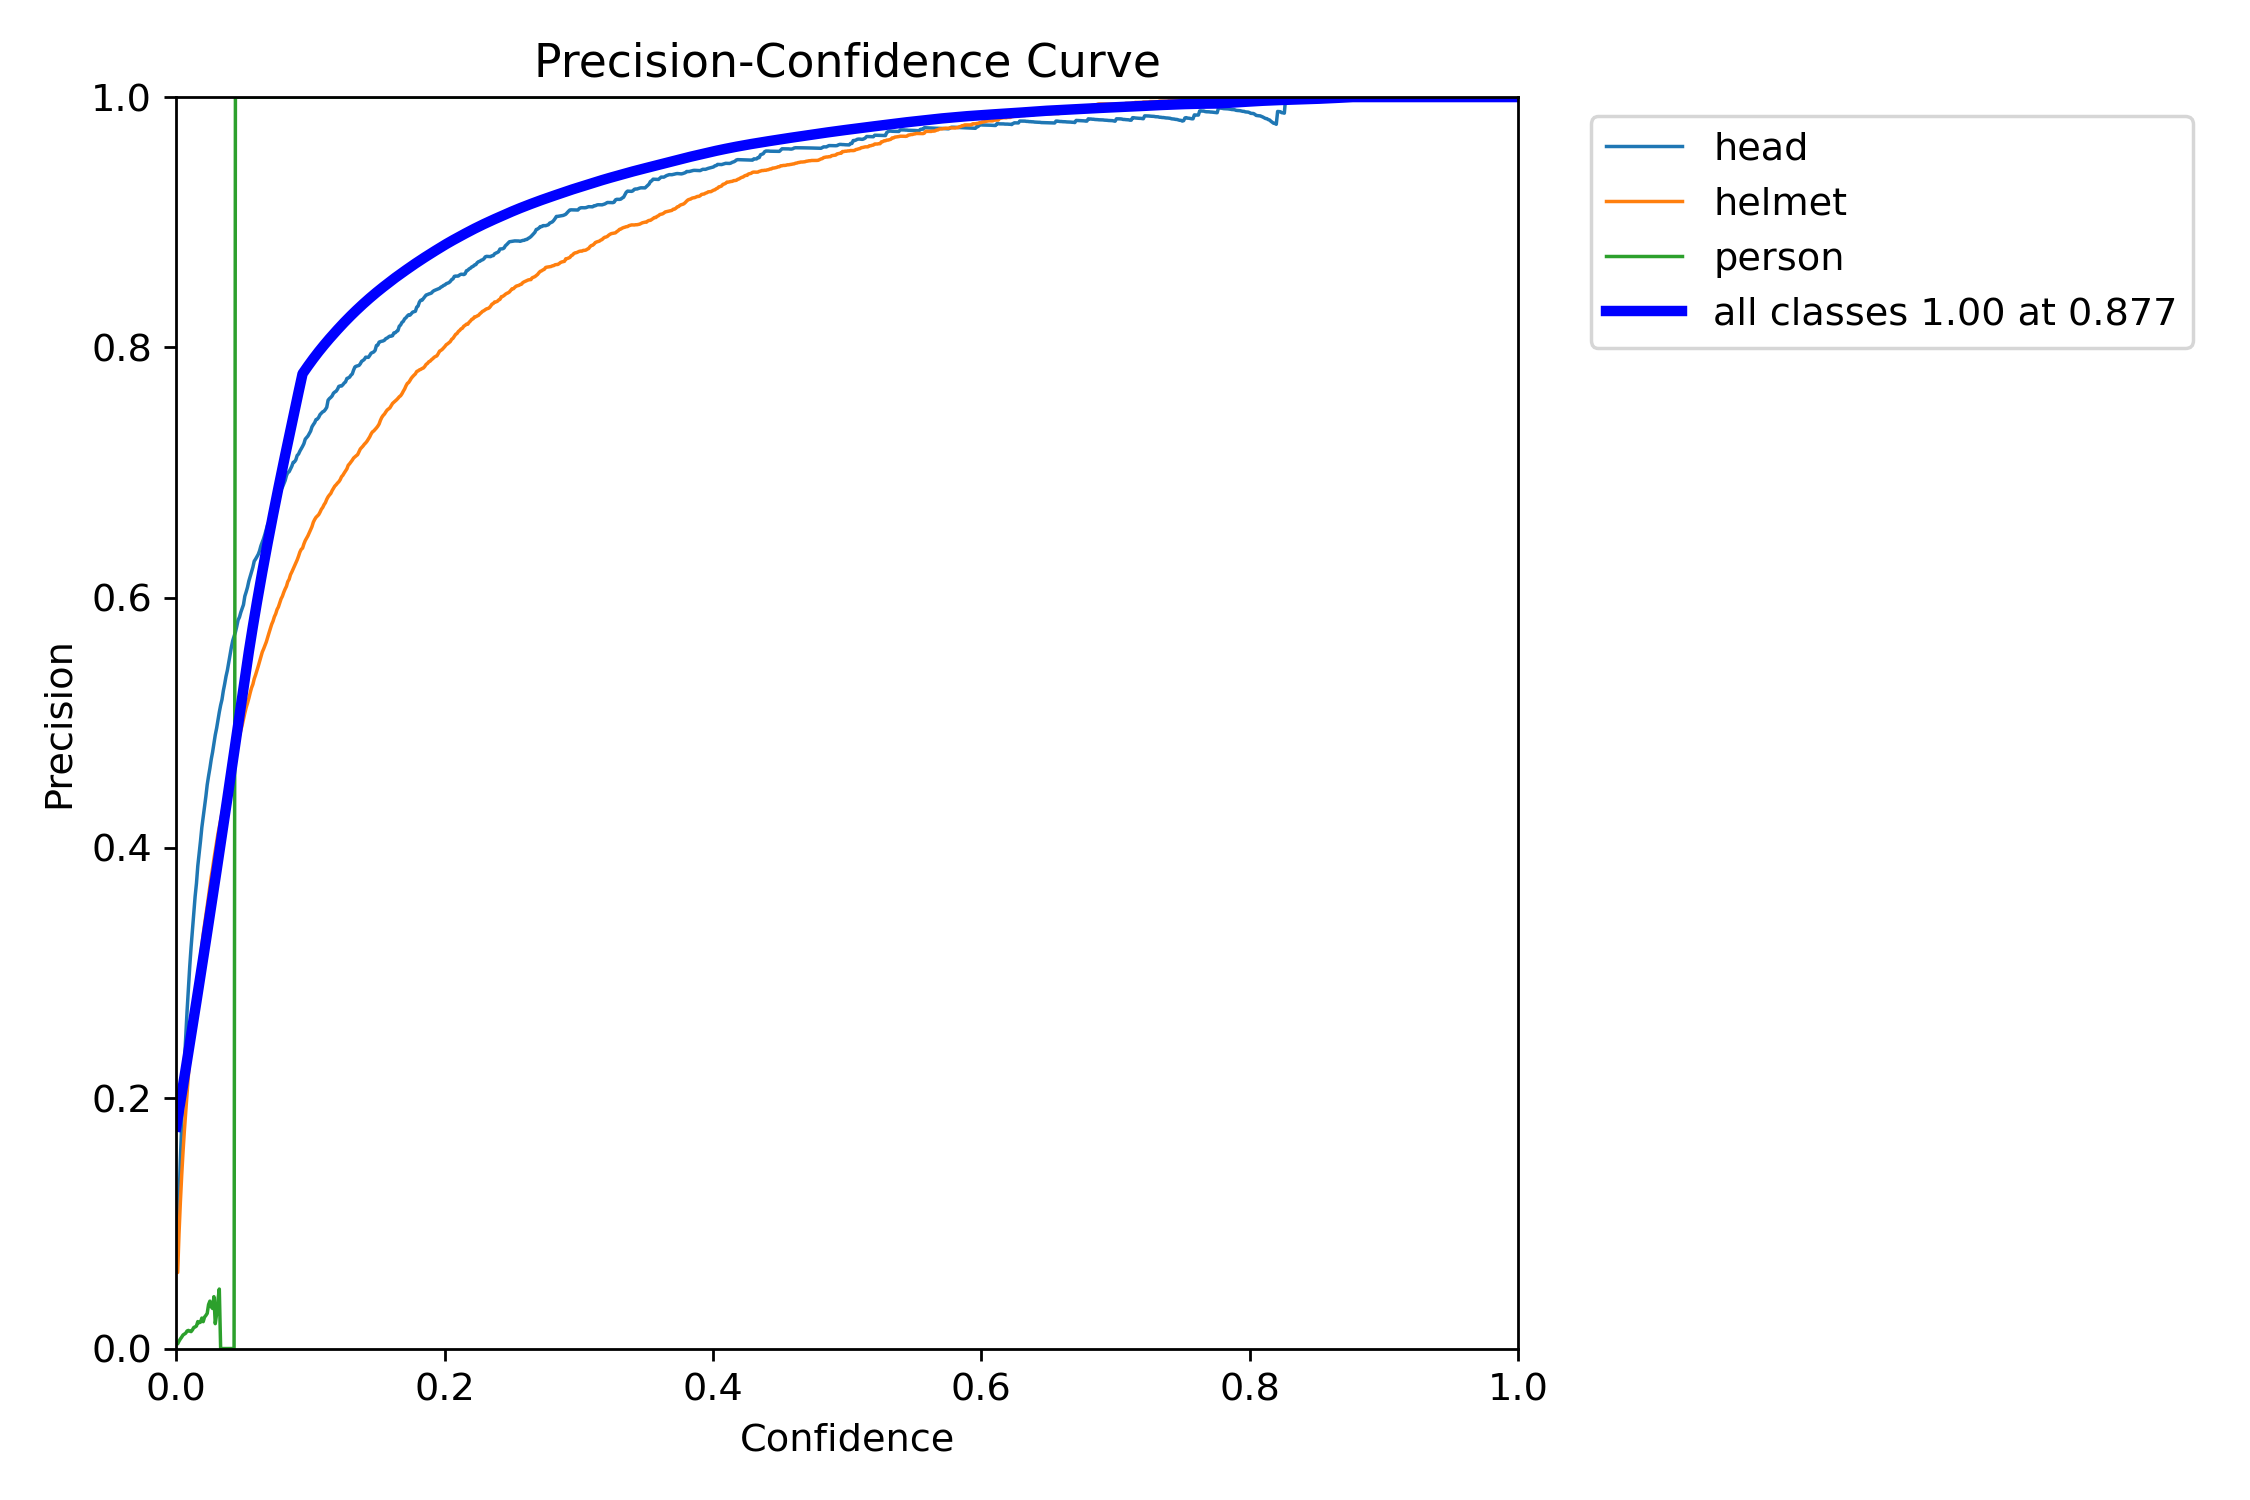

BoxR_curve.png


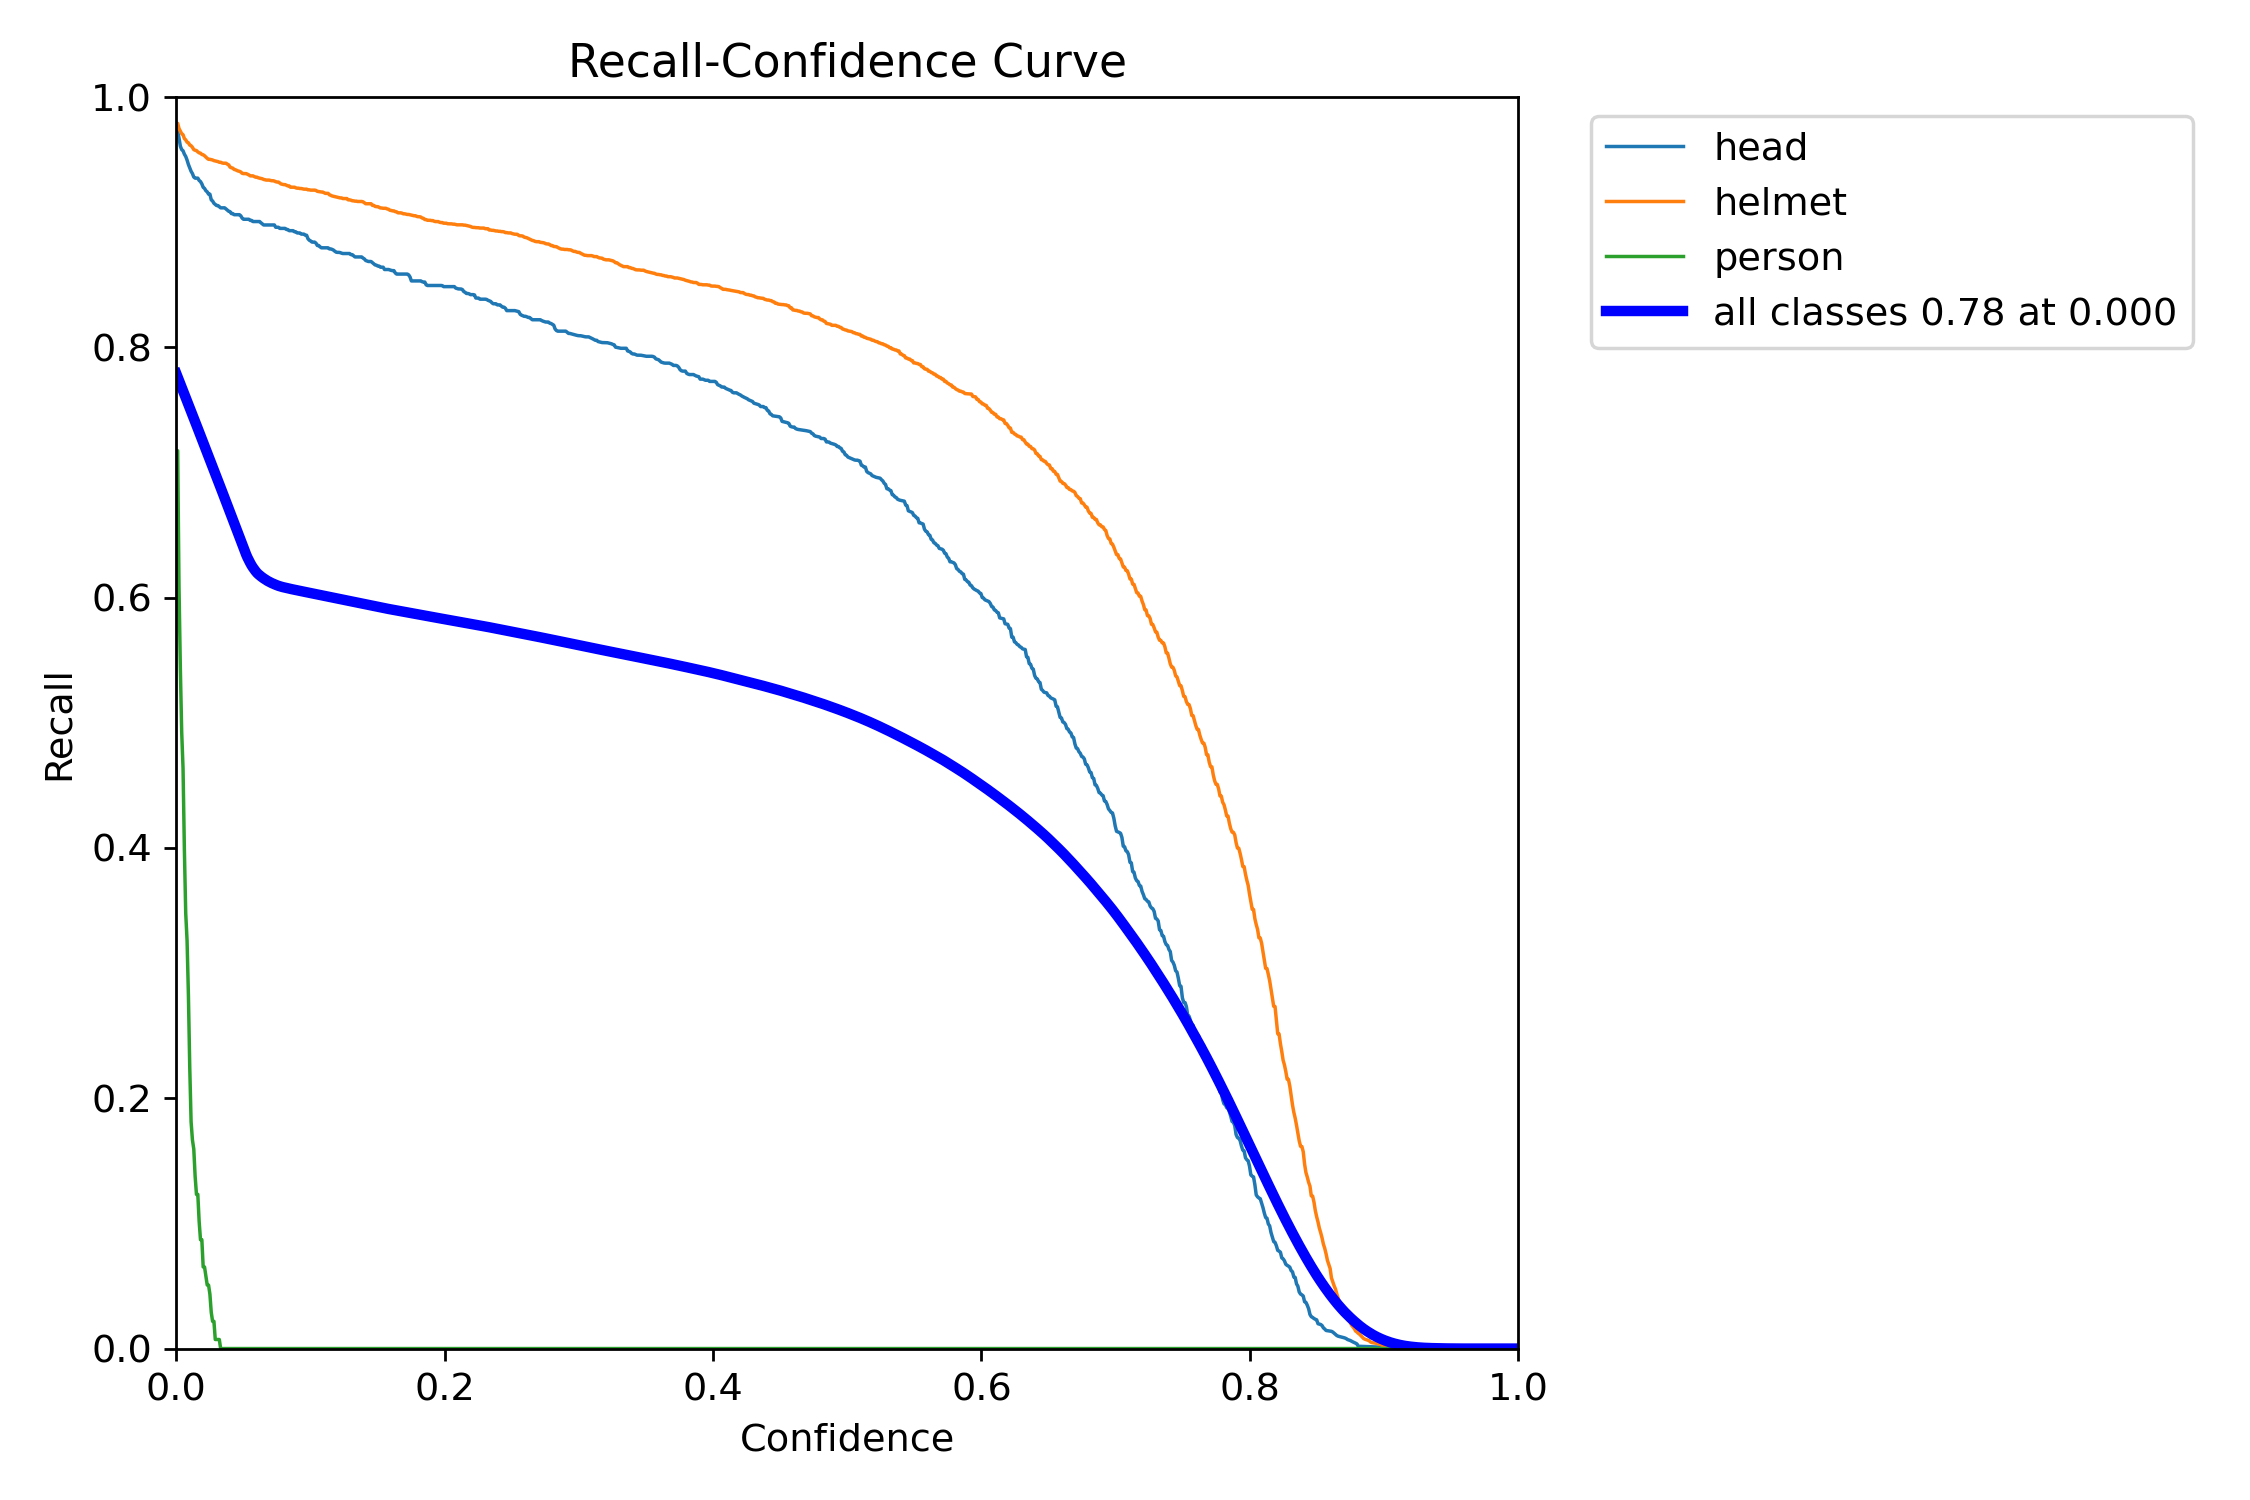

In [14]:
RUN_DIR = Path("/content/runs/hardhat/yolov8n_hardhat")
plot_files = ["results.png", "confusion_matrix.png", "BoxPR_curve.png",
              "BoxF1_curve.png", "BoxP_curve.png", "BoxR_curve.png"]

for file_name in plot_files:
    file_path = RUN_DIR / file_name
    if file_path.exists():
        print(file_name)
        display(IPyImage(filename=str(file_path)))

## 13. Evaluate on the validation set

Validation is used to monitor model performance during development. The test set remains separate for the final evaluation.

In [15]:
val_metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=416,
    device=DEVICE,
    plots=True
)

print("Validation Precision:", round(float(val_metrics.box.mp), 4))
print("Validation Recall:", round(float(val_metrics.box.mr), 4))
print("Validation mAP50:", round(float(val_metrics.box.map50), 4))
print("Validation mAP50-95:", round(float(val_metrics.box.map), 4))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1299.9±320.5 MB/s, size: 36.7 KB)
val: Scanning /content/hardhat_dataset/valid/labels.cache... 1053 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1053/1053 339.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 66/66 8.6it/s 7.6s
                   all       1053       5094      0.947      0.549       0.61      0.387
                  head        189       1096      0.936      0.789      0.893      0.566
                helmet        973       3860      0.906      0.859      0.925       0.59
                person         34        138          1          0     0.0106     0.0041
Speed: 0.4ms preprocess, 1.9ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/val
V

## 14. Final evaluation on the test set

Run this after training decisions are complete. These metrics are the final estimate on the held-out test data.

In [16]:
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=416,
    device=DEVICE,
    plots=True
)

print("TEST RESULTS")
print("Precision:", round(float(test_metrics.box.mp), 4))
print("Recall:", round(float(test_metrics.box.mr), 4))
print("mAP50:", round(float(test_metrics.box.map50), 4))
print("mAP50-95:", round(float(test_metrics.box.map), 4))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1291.2±505.6 MB/s, size: 37.0 KB)
val: Scanning /content/hardhat_dataset/test/labels... 1766 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1766/1766 1.9Kit/s 0.9s
val: New cache created: /content/hardhat_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 111/111 6.6it/s 16.8s
                   all       1766       8915      0.954      0.558      0.615      0.389
                  head        339       2208      0.939      0.809      0.903      0.566
                helmet       1604       6482      0.922      0.864      0.928      0.594
                person         45        225          1          0     0.0139     0.0063
Speed: 0.6ms preprocess, 2.2ms inference, 0.0ms loss, 1.9ms post

## 15. Per-class performance


In [17]:
print("Class names:", best_model.names)
print("Per-class AP50:", test_metrics.box.ap50)
print("Per-class AP50-95:", test_metrics.box.ap)

for class_id, class_name in best_model.names.items():
    ap50 = float(test_metrics.box.ap50[class_id]) if class_id < len(test_metrics.box.ap50) else float("nan")
    ap = float(test_metrics.box.ap[class_id]) if class_id < len(test_metrics.box.ap) else float("nan")
    print(f"{class_name}: AP50={ap50:.4f}, AP50-95={ap:.4f}")

Class names: {0: 'head', 1: 'helmet', 2: 'person'}
Per-class AP50: [     0.9027      0.9275    0.013932]
Per-class AP50-95: [    0.56645     0.59366   0.0063044]
head: AP50=0.9027, AP50-95=0.5665
helmet: AP50=0.9275, AP50-95=0.5937
person: AP50=0.0139, AP50-95=0.0063


## 16. Predict on a test image




image 1/1 /content/hardhat_dataset/test/images/005298_jpg.rf.7d1070e4a462d4c636a68e64f2013761.jpg: 416x416 8 helmets, 7.1ms
Speed: 0.9ms preprocess, 7.1ms inference, 1.5ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/hardhat_inference/image


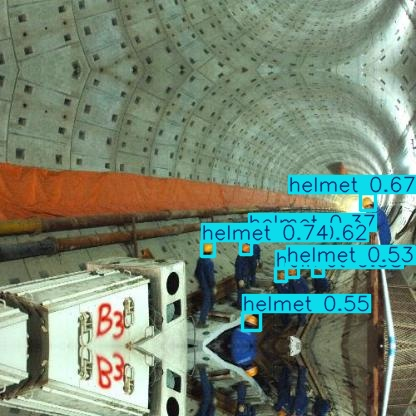

In [18]:
CONFIDENCE = 0.25

test_image_paths = get_images(DATASET_DIR / "test" / "images")
if not test_image_paths:
    raise RuntimeError("No test images found.")

IMAGE_PATH = str(test_image_paths[0])
image_results = best_model.predict(
    source=IMAGE_PATH,
    conf=CONFIDENCE,
    imgsz=416,
    save=True,
    project="/content/runs/hardhat_inference",
    name="image",
    exist_ok=True
)

display(IPyImage(filename=str(Path(image_results[0].save_dir) / Path(IMAGE_PATH).name)))

## 17. Predict on an image uploaded by the user



Saving WhatsApp Image 2026-11-24 at 8.32.17 PM.jpeg to WhatsApp Image 2026-11-24 at 8.32.17 PM.jpeg

image 1/1 /content/WhatsApp Image 2026-11-24 at 8.32.17 PM.jpeg: 288x416 3 helmets, 19.9ms
Speed: 1.6ms preprocess, 19.9ms inference, 1.7ms postprocess per image at shape (1, 3, 288, 416)
Number of detections: 3


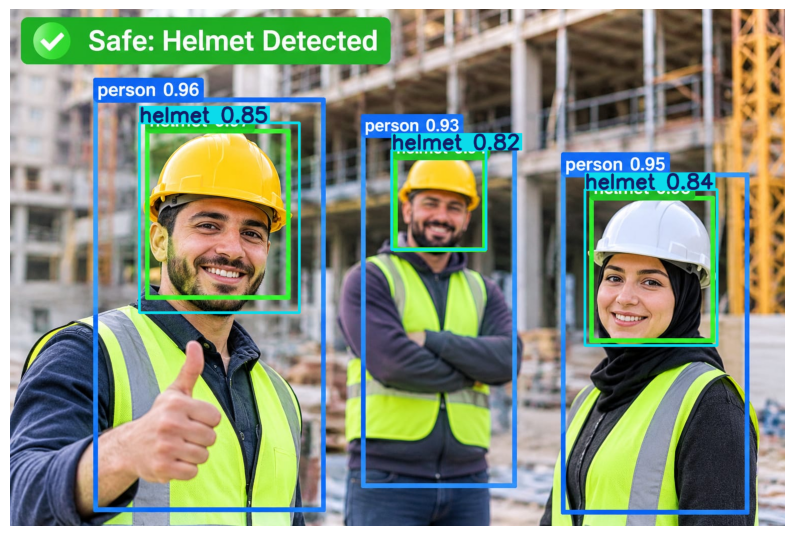

In [20]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded_image = files.upload()

if uploaded_image:
    NEW_IMAGE_PATH = list(uploaded_image.keys())[0]

    results = best_model.predict(
        source=NEW_IMAGE_PATH,
        conf=0.25,
        imgsz=416
    )

    print("Number of detections:", len(results[0].boxes))

    plt.figure(figsize=(10, 8))
    plt.imshow(results[0].plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()

## 18. Basic safety-alert prototype for one image



In [21]:
def box_xyxy(box):
    return [float(v) for v in box.xyxy[0].tolist()]

def center_in_upper_person_region(object_box, person_box, upper_fraction=0.65):
    ox = (object_box[0] + object_box[2]) / 2
    oy = (object_box[1] + object_box[3]) / 2
    px1, py1, px2, py2 = person_box
    return px1 <= ox <= px2 and py1 <= oy <= py1 + upper_fraction * (py2 - py1)

def safety_status_for_result(result):
    names = result.names
    detections = []
    for box in result.boxes:
        cls_id = int(box.cls[0])
        detections.append({
            "class": names[cls_id],
            "confidence": float(box.conf[0]),
            "xyxy": box_xyxy(box)
        })

    persons = [d for d in detections if d["class"] == "person"]
    helmets = [d for d in detections if d["class"] == "helmet"]
    heads = [d for d in detections if d["class"] == "head"]

    statuses = []
    for person in persons:
        helmet_found = any(center_in_upper_person_region(h["xyxy"], person["xyxy"]) for h in helmets)
        head_found = any(center_in_upper_person_region(h["xyxy"], person["xyxy"]) for h in heads)

        if helmet_found:
            status = "SAFE (helmet detected near upper person region)"
        elif head_found:
            status = "SAFETY ALERT (head detected, no helmet matched)"
        else:
            status = "UNCERTAIN (not enough evidence)"
        statuses.append(status)

    if not persons:
        statuses.append("UNCERTAIN: no person detection")

    return detections, statuses

single_result = best_model.predict(IMAGE_PATH, conf=CONFIDENCE, imgsz=416, verbose=False)[0]
detections, statuses = safety_status_for_result(single_result)

print("Detected objects:")
for item in detections:
    print(item["class"], round(item["confidence"], 3))
print("\nSafety status:")
for status in statuses:
    print(status)

Detected objects:
helmet 0.744
helmet 0.666
helmet 0.616
helmet 0.553
helmet 0.531
helmet 0.492
helmet 0.38
helmet 0.375

Safety status:
UNCERTAIN: no person detection


## 19. Upload a video and run object detection

The next cell processes the video frame by frame and writes an annotated MP4 file.

In [22]:
uploaded_video = files.upload()
video_candidates = [name for name in uploaded_video.keys()
                    if Path(name).suffix.lower() in [".mp4", ".avi", ".mov", ".mkv"]]

if not video_candidates:
    raise FileNotFoundError("Please upload a supported video file.")

VIDEO_PATH = video_candidates[0]
print("Video:", VIDEO_PATH)

Saving WhatsApp Video 2026-11-24 at 8.38.41 PM.mp4 to WhatsApp Video 2026-11-24 at 8.38.41 PM.mp4
Video: WhatsApp Video 2026-11-24 at 8.38.41 PM.mp4


## 20. Process video and display safety status

For each frame, we draw the YOLO detections. A frame-level alert is shown if a `head` detection exists without any helmet detection in the frame. This simple scene-level rule is intentionally labeled as a prototype; it does not prove which individual is unsafe.

For person-level status, use the separate spatial heuristic above and validate it carefully.

In [23]:
cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError("Could not open the uploaded video.")

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
if not fps or fps <= 0:
    fps = 25

OUTPUT_VIDEO = "/content/hardhat_safety_output.mp4"
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(OUTPUT_VIDEO, fourcc, fps, (width, height))

frame_count = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break

    prediction = best_model.predict(frame, conf=CONFIDENCE, imgsz=416, verbose=False)[0]
    annotated = prediction.plot()

    detected_classes = [prediction.names[int(box.cls[0])] for box in prediction.boxes]
    has_head = "head" in detected_classes
    has_helmet = "helmet" in detected_classes

    if has_head and not has_helmet:
        message = "SAFETY ALERT: HEAD DETECTED - CHECK HELMET"
        color = (0, 0, 255)
    elif has_helmet:
        message = "HELMET DETECTED"
        color = (0, 180, 0)
    else:
        message = "NO CLEAR SAFETY DECISION"
        color = (0, 165, 255)

    cv2.rectangle(annotated, (0, 0), (width, 45), (0, 0, 0), -1)
    cv2.putText(annotated, message, (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

    writer.write(annotated)
    frame_count += 1

cap.release()
writer.release()

print("Processed frames:", frame_count)
print("Saved video:", OUTPUT_VIDEO)

Processed frames: 240
Saved video: /content/hardhat_safety_output.mp4


## 21. Convert the output video for browser playback

In [24]:
!ffmpeg -y -loglevel error -i /content/hardhat_safety_output.mp4 -vcodec libx264 -pix_fmt yuv420p /content/hardhat_safety_output_fixed.mp4
display(Video("/content/hardhat_safety_output_fixed.mp4", embed=True))

## 22. Save and download the best model and output video

In [27]:
from google.colab import files

files.download(BEST_MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
files.download("/content/hardhat_safety_output_fixed.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>